# Fundamental Plane Relation

Goal: Make a 3d plot of the fundamental plane for both morphology = 0 and morphology = 0.5 elliptical galaxies

Create through a 2d plot of effective radius against velocity dispersion with a colour map of effective luminosity

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import astropy.cosmology.units as cu
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM

from scipy import stats
from scipy.optimize import curve_fit

# Merge data sets into one usable frame

In [2]:
samimorph = pd.read_csv('SAMI_Visual_Morphology/samiDR3VisualMorphology.csv')
samicat = pd.read_csv('SAMI_Input_Cat_Cluster/samiDR3InputCatClusters.csv')
samikin = pd.read_csv('SAMI_Kinematics/samiDR3StelKin.csv')

print('Sample Size of SAMI Visual Morphology Dataset:', len(samimorph))
print('Sample Size of SAMI Input Catalogue Dataset:', len(samicat))
print('Sample Size of SAMI Stellar Kinematics Dataset:', len(samikin))

Sample Size of SAMI Visual Morphology Dataset: 3068
Sample Size of SAMI Input Catalogue Dataset: 1433
Sample Size of SAMI Stellar Kinematics Dataset: 3426


In [3]:
# merging the three datasets into one data frame using the catid as the common variable

morphcat = pd.merge(samimorph, samicat, on='catid', how='inner')
df = pd.merge(morphcat, samikin, on='catid', how='inner')
print('Final Data Set', len(df))
print(df.head(20))

# Comments on output:
    # opening df a scrollable element reveals that there is quite a few NaN values in the table which
    # can potentially have an effect on our Faber-Jackson relation. These will need to be filtered out.

Final Data Set 962
    Unnamed: 0_x       catid  type  Unnamed: 0_y     ra_obj   dec_obj  \
0           2151  9008500001   0.0           849  10.460211 -9.303184   
1           2152  9008500002   0.0           850  10.460158 -9.303645   
2           2153  9008500004   1.5           851  10.456779 -9.295304   
3           2154  9008500007   0.0           852  10.450953 -9.284216   
4           2154  9008500007   0.0           852  10.450953 -9.284216   
5           2155  9008500018   0.5           853  10.489803 -9.281996   
6           2156  9008500020   0.0           854  10.422118 -9.315872   
7           2157  9008500022   0.5           855  10.436680 -9.338163   
8           2158  9008500024   0.5           856  10.417239 -9.304267   
9           2159  9008500034   1.0           857  10.470191 -9.358393   
10          2160  9008500042   0.0           858  10.400896 -9.325084   
11          2161  9008500043   3.0           859  10.426972 -9.357179   
12          2162  9008500059   0

For morphology == 0 elliptical galaxies

In [4]:
elliptical0 = df[df['type'] == 0.0] # choosing only elliptical galaxies
# key defines elliptical galaxies as having the type = 0
    # 0.5 is for galaxies between elliptical and lenticular stages

print('Number of Elliptical Galaxies:', len(elliptical0))

# fundamental plane needs effective radius, velocity dispersion and effective brightness
rawdf0 = elliptical0[['catid', 'mu_1re', 'sigma_re', 'r_e', 'z_spec']]
print('Uncleaned Data Set:', len(rawdf0))
print(rawdf0.head(20))
    # mu_1re is in magnitude/arcsec^2, sigma_re is in km/s, r_e is in arcsec
    # we're going to have unit problems as effective radius needs to be in kpc


Number of Elliptical Galaxies: 152
Uncleaned Data Set: 152
         catid     mu_1re    sigma_re        r_e    z_spec
0   9008500001  22.194613         NaN  21.041311  0.055385
1   9008500002  22.220806         NaN  21.361086  0.055385
3   9008500007  20.561842  265.057370   3.103812  0.052969
4   9008500007  20.561842         NaN   3.103812  0.052969
6   9008500020  22.480024  170.477860   5.972856  0.047709
10  9008500042  20.710413  202.322860   1.794834  0.054516
12  9008500059  22.171244  204.846340   3.855160  0.057958
14  9008500064  21.802141  125.197975   1.496453  0.059343
16  9008500068  21.571623   87.443590   2.001808  0.056975
20  9008500077  22.191960  183.164600   4.590606  0.066115
27  9008500096  22.008698  164.250000   5.947524  0.046795
34  9008500114  22.396560         NaN   8.146433  0.057789
36  9008500118  22.136293  122.640700   3.118104  0.055625
44  9008500138  20.584938  114.042900   1.077231  0.054311
45  9008500139  21.034206  131.962300   2.163436  0.0516

In [5]:
elliptical05 = df[df['type'] == 0.5] # choosing only elliptical galaxies
# key defines elliptical galaxies as having the type = 0
    # 0.5 is for galaxies between elliptical and lenticular stages

print('Number of Elliptical Galaxies:', len(elliptical05))

# fundamental plane needs effective radius, velocity dispersion and effective brightness
rawdf05 = elliptical05[['catid', 'mu_1re', 'sigma_re', 'r_e', 'z_spec']]
print('Uncleaned Data Set:', len(rawdf05))
print(rawdf05.head(20))
    # mu_1re is in magnitude/arcsec^2, sigma_re is in km/s, r_e is in arcsec
    # we're going to have unit problems as effective radius needs to be in kpc


Number of Elliptical Galaxies: 128
Uncleaned Data Set: 128
          catid     mu_1re    sigma_re        r_e    z_spec
5    9008500018  20.182903  130.505040   0.930207  0.057178
7    9008500022  21.249514   98.179590   1.641169  0.046343
8    9008500024  20.904030  187.108870   2.937215  0.056015
38   9008500122  21.392720  129.695770   2.260992  0.056426
40   9008500130  20.803759         NaN   1.409129  0.053946
41   9008500134  20.065487  151.563870   1.042572  0.051158
42   9008500135  24.062752         NaN  27.826975  0.056236
49   9008500160  20.960442   94.033200   2.176188  0.057395
60   9008500193  20.540434  121.194030   1.199098  0.057039
62   9008500197  21.775751  113.182630   2.262533  0.061266
65   9008500208  21.019482         NaN   2.113636  0.052967
79   9008500240  22.166332  107.679016   2.781194  0.057110
80   9008500245  22.570711  259.273900   6.771205  0.053882
82   9008500249  22.887806  117.748024   4.004406  0.058168
101  9008500339  22.944153  102.274740   

# Cleaning Datasets

Both ellipticals 0 and 0.5 have numerous NaN values in the values we plan to use whic can cause problems in our representation of the fundamental plane

For ellipticals where morphology = 0

In [6]:
NaNtotal0 = len(elliptical0[elliptical0['mu_1re'].isnull() | elliptical0['sigma_re'].isnull() | elliptical0['r_e'].isnull()])
print("Total number of NaN value rows in data frame:", NaNtotal0)

Total number of NaN value rows in data frame: 45


In [7]:
df_clean_elliptical0 = rawdf0.dropna(subset = ['mu_1re', 'sigma_re', 'r_e', 'z_spec'])

print('Cleaned Data Set', len(df_clean_elliptical0))
print(df_clean_elliptical0.head(20))

RemovedSamples0 = len(rawdf0) - len(df_clean_elliptical0)
print('Number of Samples Removed:', RemovedSamples0)

print('Does Removed Samples = Total NaN values?', RemovedSamples0 == NaNtotal0)

# Now we want to check that elliptical dataframe has unique values for catid 
# As this can influence the resulting graphs when plotted ie. if 2 of the same catid
# That will get twice the influence of the other catid values
uniquecatids = df_clean_elliptical0['catid'].nunique()
print('Number of unique catid values in elliptical Dataframe:', uniquecatids)
print("Does unique catid values = total number of rows in elliptical dataframe?", uniquecatids == len(df_clean_elliptical0))

Cleaned Data Set 107
          catid     mu_1re    sigma_re       r_e    z_spec
3    9008500007  20.561842  265.057370  3.103812  0.052969
6    9008500020  22.480024  170.477860  5.972856  0.047709
10   9008500042  20.710413  202.322860  1.794834  0.054516
12   9008500059  22.171244  204.846340  3.855160  0.057958
14   9008500064  21.802141  125.197975  1.496453  0.059343
16   9008500068  21.571623   87.443590  2.001808  0.056975
20   9008500077  22.191960  183.164600  4.590606  0.066115
27   9008500096  22.008698  164.250000  5.947524  0.046795
36   9008500118  22.136293  122.640700  3.118104  0.055625
44   9008500138  20.584938  114.042900  1.077231  0.054311
45   9008500139  21.034206  131.962300  2.163436  0.051665
52   9008500169  21.824500  173.848070  4.282817  0.060642
57   9008500182  21.654446  166.522140  2.966546  0.054802
71   9008500225  21.080845  232.152270  3.470791  0.056105
74   9008500234  22.053015  213.418180  5.881770  0.055719
92   9008500303  22.070808  187.230

For ellipticals where morphology = 0.5

In [8]:
NaNtotal05 = len(rawdf05[rawdf05['mu_1re'].isnull() | rawdf05['sigma_re'].isnull() | rawdf05['r_e'].isnull()])
print("Total number of NaN value rows in data frame:", NaNtotal05)

Total number of NaN value rows in data frame: 32


In [9]:
df_clean_elliptical05 = rawdf05.dropna(subset = ['mu_1re', 'sigma_re', 'r_e', 'z_spec'])

print('Cleaned Data Set', len(df_clean_elliptical05))
print(df_clean_elliptical05.head(20))

RemovedSamples05 = len(rawdf05) - len(df_clean_elliptical05)
print('Number of Samples Removed:', RemovedSamples05)

print('Does Removed Samples = Total NaN values?', RemovedSamples05 == NaNtotal05)

# Now we want to check that elliptical dataframe has unique values for catid 
# As this can influence the resulting graphs when plotted ie. if 2 of the same catid
# That will get twice the influence of the other catid values
uniquecatids = df_clean_elliptical05['catid'].nunique()
print('Number of unique catid values in elliptical Dataframe:', uniquecatids)
print("Does unique catid values = total number of rows in elliptical dataframe?", uniquecatids == len(df_clean_elliptical05))

Cleaned Data Set 96
          catid     mu_1re    sigma_re       r_e    z_spec
5    9008500018  20.182903  130.505040  0.930207  0.057178
7    9008500022  21.249514   98.179590  1.641169  0.046343
8    9008500024  20.904030  187.108870  2.937215  0.056015
38   9008500122  21.392720  129.695770  2.260992  0.056426
41   9008500134  20.065487  151.563870  1.042572  0.051158
49   9008500160  20.960442   94.033200  2.176188  0.057395
60   9008500193  20.540434  121.194030  1.199098  0.057039
62   9008500197  21.775751  113.182630  2.262533  0.061266
79   9008500240  22.166332  107.679016  2.781194  0.057110
80   9008500245  22.570711  259.273900  6.771205  0.053882
82   9008500249  22.887806  117.748024  4.004406  0.058168
101  9008500339  22.944153  102.274740  5.028500  0.058460
103  9008500351  20.938751  139.870180  2.435606  0.054658
105  9008500359  21.318617  151.968610  1.926707  0.055318
124  9008500533  20.745232  105.427520  1.423418  0.055855
126  9008500542  22.024480   77.6164

There should now be no NaN values or double counts

# Converting to Parameters used in the Fundamental Plane

This includes the log10 of the effective radius and velocity dispersion as well as converting arcseconds to kilo parsecs

In [10]:
# 1 arcsec = (1 parsec)^-1 (small angle approximation such that tan(theta)~theta)

# using DAVID'S REDSHIFT METHOD USING ASTROPY
H0 = 70 # Hubble constant
Om0 = 0.3 # Present day matter desnity

cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)

# Distances from Earth calculated using Redshift.
el_zero_d = cosmo.comoving_distance(pd.to_numeric(df_clean_elliptical0['z_spec']) * cu.redshift);
el_half_d = cosmo.comoving_distance(pd.to_numeric(df_clean_elliptical05['z_spec']) * cu.redshift);

# Now, require R_E = r_e * d.
el_zero_RE = df_clean_elliptical0['r_e'] * el_zero_d;
el_half_RE = df_clean_elliptical05['r_e'] * el_half_d;

In [11]:
log_re0 = np.log10(el_zero_RE)
log_re05 = np.log10(el_half_RE)

log_sigma0 = np.log10(df_clean_elliptical0['sigma_re'])
log_sigma05 = np.log10(df_clean_elliptical05['sigma_re'])

mu_e0 = df_clean_elliptical0['mu_1re']
mu_e05 = df_clean_elliptical05['mu_1re']

# Plotting the Fundamental Plane

Fundamental Plane equation:

log10(effective radius) = a * log10(velocity dispersion) + b * brightness at an effective radius + c

Hyde & Bernardi (2009) stated in the paper 'The luminosity and stellar mass Fundamental plane of early-type galaxies' that a = 1.1701 and b = 0.3029

In [12]:
a = 1.1701
b = 0.3029
fp0 = a * log_sigma0 + b * mu_e0
fp05 = a * log_sigma05 + b * mu_e05

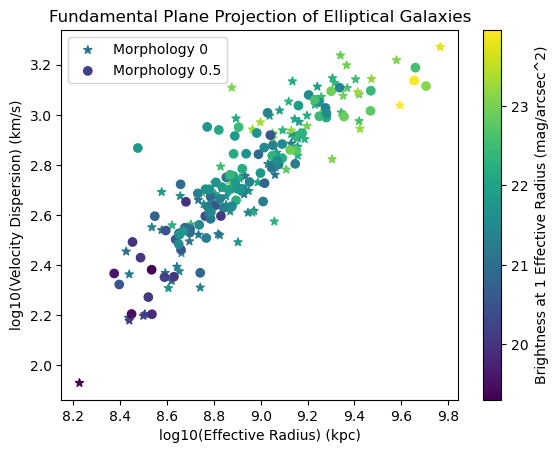

In [13]:
plt.scatter(fp0, log_re0, marker='*', c=mu_e0, label='Morphology 0')
plt.scatter(fp05, log_re05, marker='o', c=mu_e05, label='Morphology 0.5')

plt.xlabel('log10(Effective Radius) (kpc)')
plt.ylabel('log10(Velocity Dispersion) (km/s)')
plt.title("Fundamental Plane Projection of Elliptical Galaxies")

cbar = plt.colorbar()
cbar.set_label('Brightness at 1 Effective Radius (mag/arcsec^2)')
plt.legend();

plt.show()

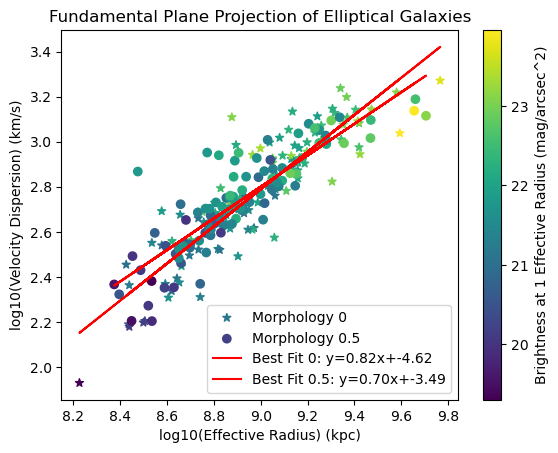

In [14]:
# Trying to get a fit

m0, b0 = np.polyfit(fp0, log_re0, 1)
m05, b05 = np.polyfit(fp05, log_re05, 1)

plt.scatter(fp0, log_re0, marker='*', c=mu_e0, label='Morphology 0')
plt.scatter(fp05, log_re05, marker='o', c=mu_e05, label='Morphology 0.5')

plt.xlabel('log10(Effective Radius) (kpc)')
plt.ylabel('log10(Velocity Dispersion) (km/s)')
plt.title("Fundamental Plane Projection of Elliptical Galaxies")

cbar = plt.colorbar()
cbar.set_label('Brightness at 1 Effective Radius (mag/arcsec^2)')

plt.plot(fp0, m0 * fp0 + b0, color="red", label=f"Best Fit 0: y={m0:.2f}x+{b0:.2f}")

plt.plot(fp05, m05 * fp05 + b05, color="red", label=f"Best Fit 0.5: y={m05:.2f}x+{b05:.2f}")


plt.legend()

plt.show()

